# Práctica — Leyes de potencia y periodicidades en hipnogramas

**Licenciatura en Inteligencia Artificial**

**Autores**
- [Kevin Vargas Flores](mailto:kevinvargasflores505@gmail.com)




Los archivos CSV que se comparten contienen hipnogramas de registros de aproximadamente **8 horas** de sueño. Cada fila corresponde a un **segmento de 30 segundos**. La primera columna es el número de segmento y la segunda es la etapa de sueño codificada de la siguiente manera:

| Código | Etapa |
|---|---|
| 0 | Vigilia (W) |
| 1 | Etapa 1 |
| 2 | Etapa 2 |
| 3 | Etapa 3 |
| 4 | Etapa 4 |
| 5 | REM (MOR) |
| 6 | Movimiento |
| 7 | Sin clasificar |

> **Tiempo-vida (lifetime):** duración de una racha consecutiva de un mismo símbolo. Por ejemplo, en la secuencia `... 2 2 2 5 ...` la etapa 2 tiene un tiempo-vida de 3 segmentos = 90 segundos. Todo el análisis de esta práctica se construye sobre esta magnitud.

- 6 y 7 = Artefacto

- 3 y 4 = Deep Sleep

- 0,1, 2 y 5 = etapas

---

Trabajar con el grupo 2 e I

1=Registros de la primera noche <br>
2= Registros de la segunda noche <br>
i= insomnio



## Objetivos

Al terminar esta práctica deberás ser capaz de:

1. Generar los gráficos **tiempo-vida de las fases de sueño vs. frecuencia** (en escala log-log) de cada hipnograma.
2. Estimar el exponente de la ley de potencia $\alpha$ mediante **regresión por mínimos cuadrados (OLS)** sobre el log-log (tiempo-vida vs. frecuencia), reportando **p-valor y $R^2$**; y contrastar con el **método de Clauset** (máxima verosimilitud + estimación de $x_{\min}$ + p-valor por Monte Carlo), usando el paquete `powerlaw`. Estimar el p-valor en ambos casos **e interpretarlo**.
3. Comparar ambos métodos y **justificar cuál es mejor**.
4. Repetir el análisis completo (puntos 1, 2 y 3) con **bigramas, trigramas, ..., 7-gramas**.
5. Concluir **qué $n$-grama se parece más a una ley de potencia**.
6. Elegir **una medida de teoría de la información** (entropía marginal, entropía conjunta, entropía condicional o información mutua, de manera univariada) para buscar **periodicidades** en la dinámica de cada registro.
7. Generar los gráficos de la medida elegida **en función del retardo $\tau$** e interpretar si existe evidencia de comportamiento periódico.


## 6. Teoría de la información: buscando periodicidades

**Elige UNA** de las siguientes medidas y justifica tu elección:

| Medida | Definición | Qué revela |
|---|---|---|
| Entropía marginal | $H(X) = -\sum_x p(x)\log_2 p(x)$ | Uniformidad del histograma de etapas |
| Entropía conjunta | $H(X_t, X_{t+\tau})$ | Incertidumbre conjunta a retardo $\tau$ |
| Entropía condicional | $H(X_{t+\tau}\mid X_t) = H(X_t,X_{t+\tau}) - H(X_t)$ | Incertidumbre residual del futuro dado el presente |
| Información mutua | $I(X_t;X_{t+\tau}) = H(X_t)+H(X_{t+\tau})-H(X_t,X_{t+\tau})$ | Redundancia compartida; **picos en los retardos periódicos** |

La idea: si la dinámica tiene un **período $T$**, muestrear la señal cada $\tau = T, 2T, \dots$ la alinea consigo misma. Esperamos entonces: **mínimos** en $H(\tau)$ (menor sorpresa) o **máximos** en $I(\tau)$ (máxima dependencia) en esos retardos. En el sueño, el candidato fisiológico es el **ciclo ultradiano de ~90 min ≈ 180 segmentos** (≈ 1.5 h).

## 7. Interpretación de los resultados

1. **Describe la forma de la curva**: ¿hay mínimos locales de la entropía (o máximos de la información mutua)? ¿En qué valores de $\tau$ aparecen?
2. **Relación con la fisiología**: ¿coinciden con el ciclo de ~90 min? ¿Se observan armónicos ($\tau \approx 3$ h)?
3. **Comparación entre registros**: ¿el patrón es consistente entre archivos?
4. **Artefactos**: discute el efecto de las etapas 6 (Movimiento) y 7 (Sin clasificar). Opcional: repite la figura **excluyéndolas** (reemplázalas o filtra la señal) y compara.
5. **Conclusión**: ¿hay evidencia estadística/estructural de comportamiento periódico en la dinámica univariada de los hipnogramas? Argumenta a favor o en contra, y conecta con lo encontrado en el punto 5 (¿cambia la respuesta con el $n$-grama elegido?).

---

## Entregables
- Notebook ejecutado (código + salidas) con las figuras de los puntos 1, 4 y 7.
- Tablas resumen de los puntos 2 y 4 (con **interpretación escrita** de p-valores y $R^2$).
- Discusión de los puntos 3, 5 y 7 en celdas markdown.



## Rúbrica TENTATIVA (100 pts)
| Criterio | Pts |
|---|---|
| Gráficos log-log correctos y completos (pts. 1) | 15 |
| Estimación e interpretación OLS + Clauset (pt. 2) | 25 |
| Comparación y justificación de métodos (pt. 3) | 15 |
| Análisis n-gramas + tabla + conclusión (pts. 4–5) | 20 |
| Medida de información, figuras e interpretación (pts. 6–7) | 15 |
| Calidad del notebook y del informe | 10 |

# Práctica

## Hipotesis

### Hipótesis Nula $H_0$
Todos los muestreos de las personas en este estudio del sueño presentaran un 

## Exportación de los datos

In [1]:
#Librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

In [2]:
# Dataset
# URL directa (raw) del CSV en GitHub
scoring_combined_csv = 'https://raw.githubusercontent.com/kao05/DS_ComplexSystem/main/Hipnogramas/scoring_combined.csv'
df_resultados_ols = 'https://raw.githubusercontent.com/kao05/DS_ComplexSystem/main/Hipnogramas/resultados_ols_29_hipnogramas.csv'

# Leer el CSV directamente a un DataFrame
df = pd.read_csv(scoring_combined_csv)
df_ols = pd.read_csv(df_resultados_ols)

In [3]:
#Procesamiento de los datos
#Libreria
#df = pd.read_csv('scoring_combined.csv')
hipnogramas = {
    nombre: grupo['scor_clean'].reset_index(drop=True)
    for nombre, grupo in df.groupby('name')
}
print(f"Total de hipnogramas: {len(hipnogramas)}")
print(f"Sujetos disponibles: {list(hipnogramas.keys())[:5]} ...")

Total de hipnogramas: 29
Sujetos disponibles: ['Scoring_AA_1', 'Scoring_AG_1', 'Scoring_AQ_1', 'Scoring_AR_1', 'Scoring_AR_2'] ...


In [4]:
#Verificacion del lifetime
for sujeto, serie_hipnograma in hipnogramas.items():
    num_epocas = len(serie_hipnograma)
    duracion_horas = (num_epocas * 30) / 3600
    print(f"Sujeto: {sujeto} | Épocas: {num_epocas} | Duración: {duracion_horas:.2f} h")

    # Aquí irá la función de extracción de lifetimes L para este hipnograma específico

Sujeto: Scoring_AA_1 | Épocas: 858 | Duración: 7.15 h
Sujeto: Scoring_AG_1 | Épocas: 920 | Duración: 7.67 h
Sujeto: Scoring_AQ_1 | Épocas: 864 | Duración: 7.20 h
Sujeto: Scoring_AR_1 | Épocas: 1061 | Duración: 8.84 h
Sujeto: Scoring_AR_2 | Épocas: 977 | Duración: 8.14 h
Sujeto: Scoring_AV_1 | Épocas: 798 | Duración: 6.65 h
Sujeto: Scoring_BP_1 | Épocas: 805 | Duración: 6.71 h
Sujeto: Scoring_CG_i | Épocas: 824 | Duración: 6.87 h
Sujeto: Scoring_DG_2 | Épocas: 1055 | Duración: 8.79 h
Sujeto: Scoring_DJ_i | Épocas: 870 | Duración: 7.25 h
Sujeto: Scoring_ED_i | Épocas: 899 | Duración: 7.49 h
Sujeto: Scoring_EL_1 | Épocas: 1219 | Duración: 10.16 h
Sujeto: Scoring_EL_2 | Épocas: 947 | Duración: 7.89 h
Sujeto: Scoring_EP_1 | Épocas: 906 | Duración: 7.55 h
Sujeto: Scoring_GA_2 | Épocas: 1023 | Duración: 8.53 h
Sujeto: Scoring_IN_1 | Épocas: 1109 | Duración: 9.24 h
Sujeto: Scoring_IN_2 | Épocas: 981 | Duración: 8.18 h
Sujeto: Scoring_JM_i | Épocas: 797 | Duración: 6.64 h
Sujeto: Scoring_JS_2 |

In [5]:
hipnogramas_np = {
    nombre: grupo['scor_clean'].to_numpy()
    for nombre, grupo in df.groupby('name')
}

## Lifetime de las fases de sueño vs frecuencia

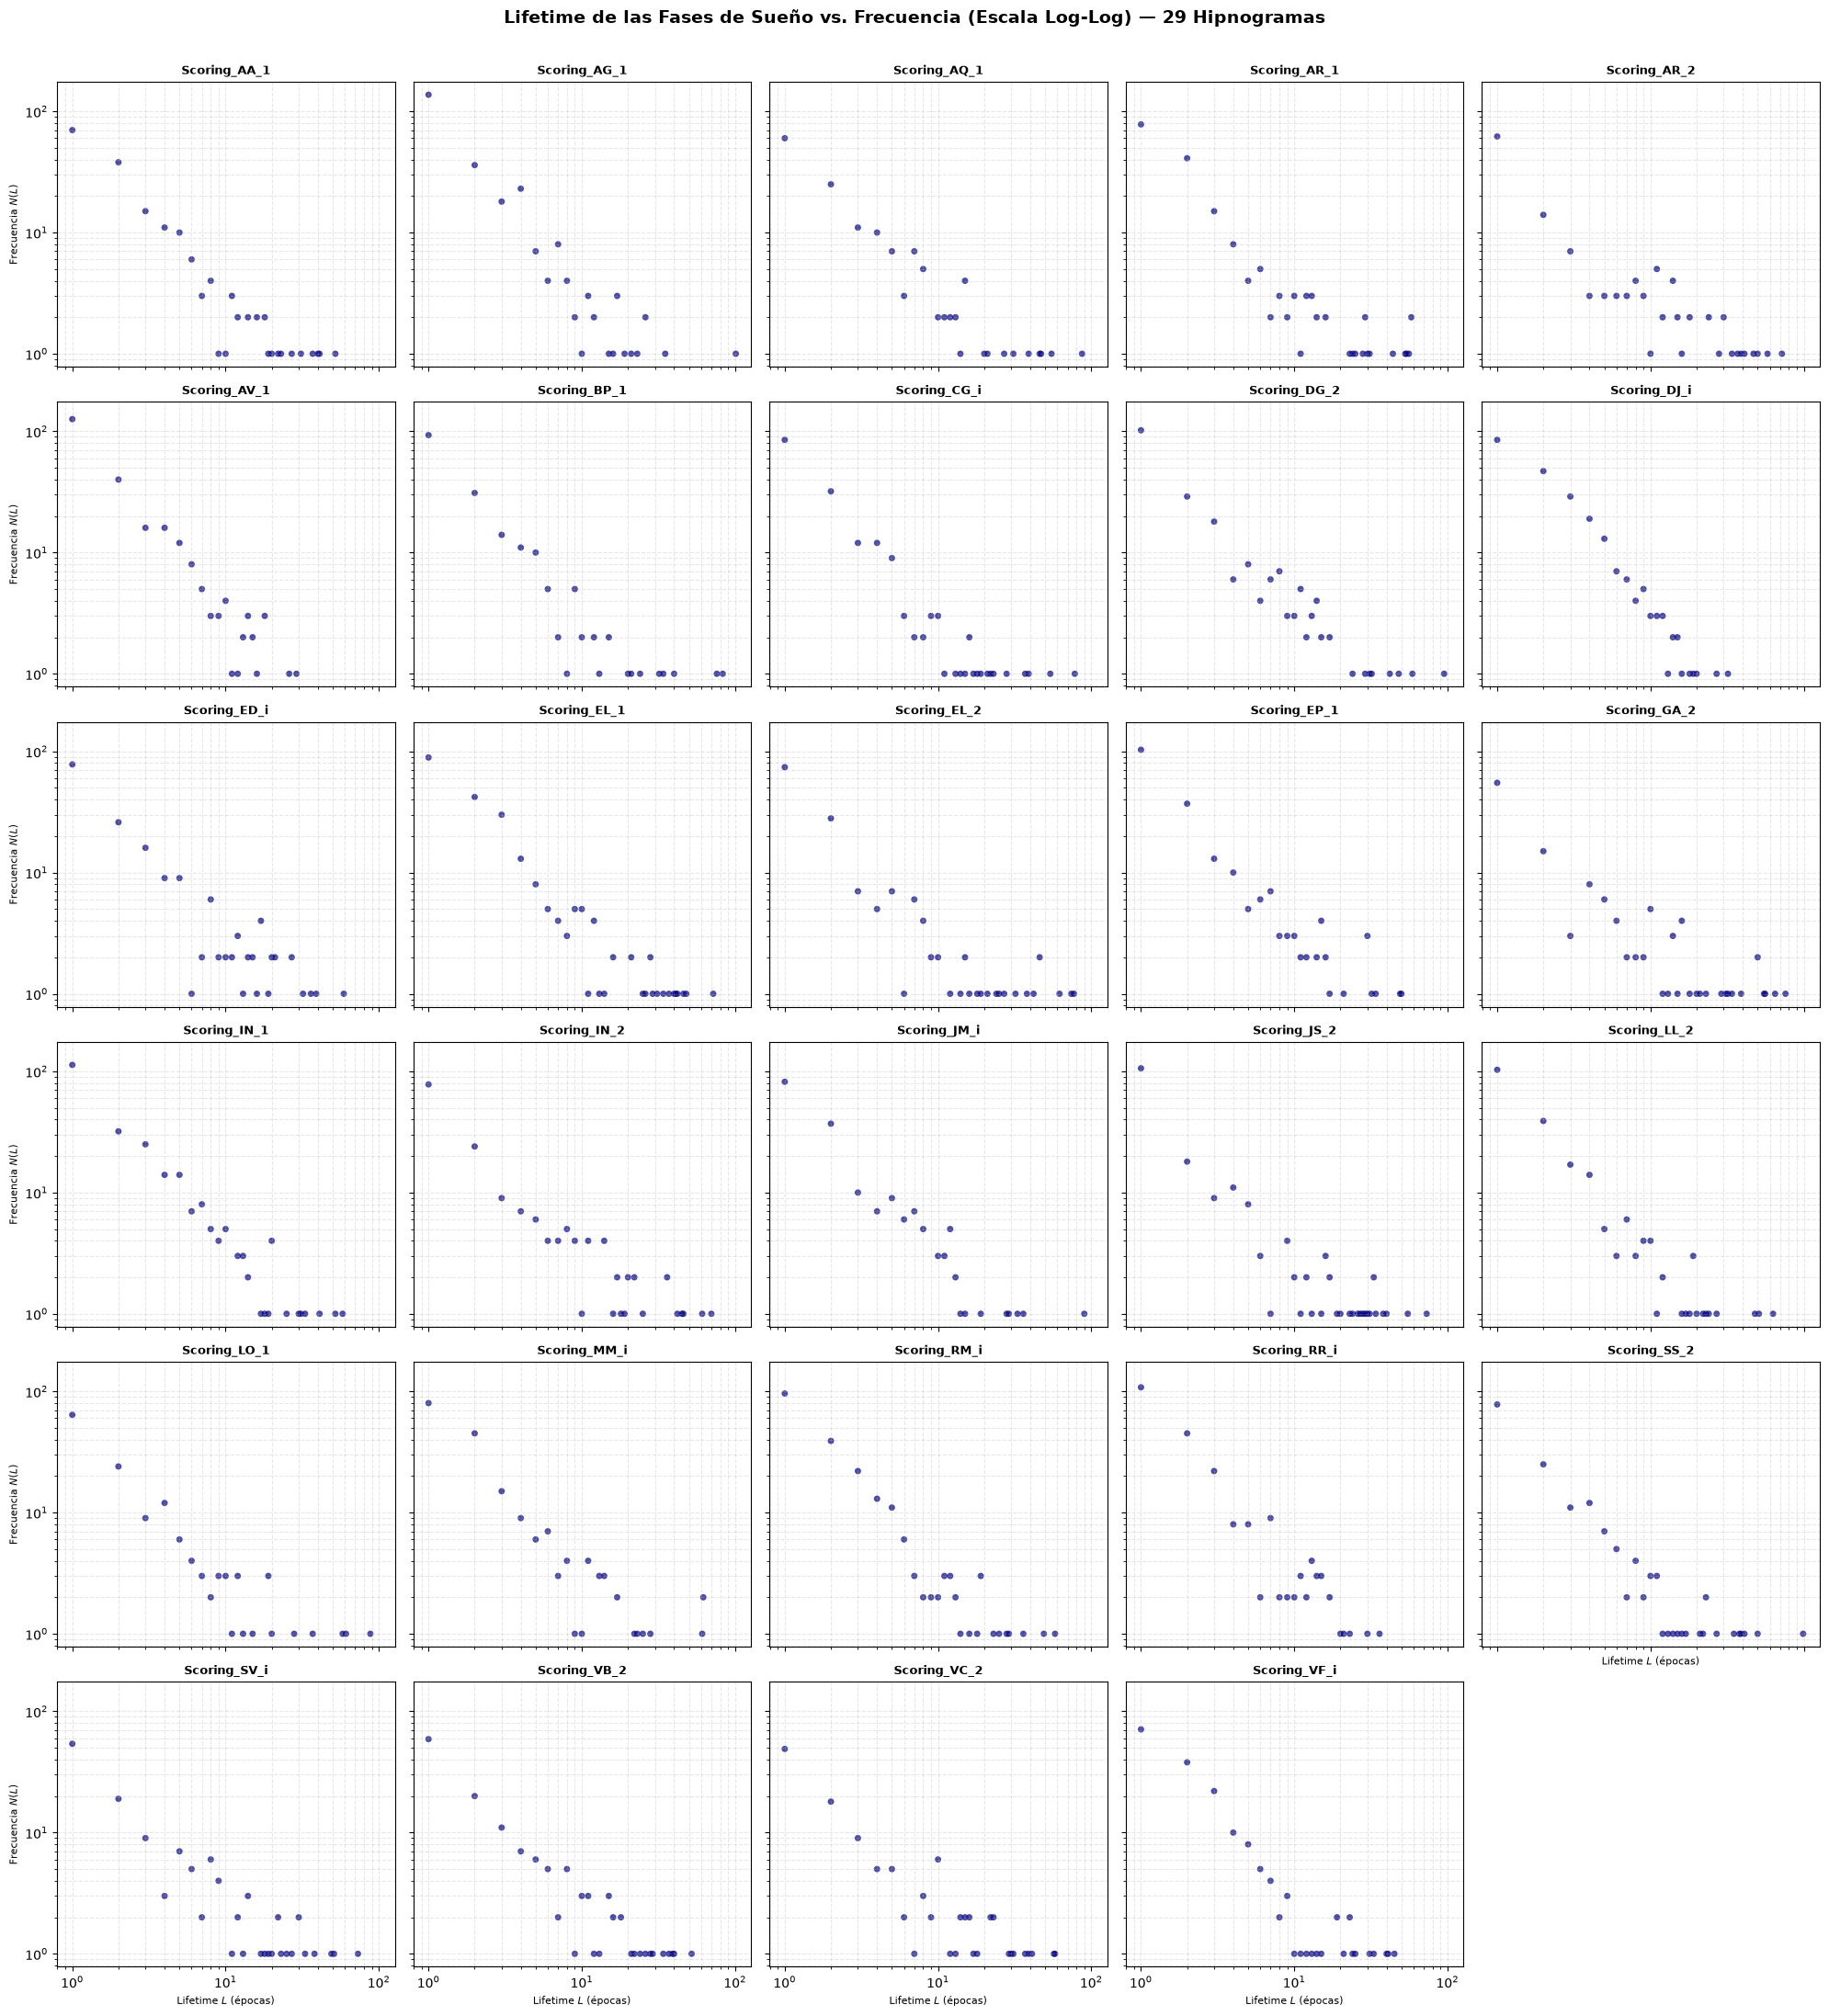

In [6]:
def calcular_lifetimes(sequence: np.ndarray) -> np.ndarray:
    """
    Calcula la duración (en número de épocas) de cada racha ininterrumpida
    de un mismo estado en la secuencia del hipnograma.
    """
    if len(sequence) == 0:
        return np.array([])
    # Identificar puntos de cambio entre épocas
    cambios = np.diff(sequence) != 0
    indices = np.concatenate(([0], np.where(cambios)[0] + 1, [len(sequence)]))
    lifetimes = np.diff(indices)
    return lifetimes

# Generación del panel de 29 hipnogramas en escala log-log
fig, axes = plt.subplots(6, 5, figsize=(20, 22), sharex=True, sharey=True)
axes = axes.flatten()

sujetos = list(hipnogramas.keys())

for i, sujeto in enumerate(sujetos):
    ax = axes[i]
    lfts = calcular_lifetimes(hipnogramas[sujeto])

    # Conteo de frecuencias de cada lifetime
    valores, conteos = np.unique(lfts, return_counts=True)

    ax.scatter(valores, conteos, color='navy', alpha=0.7, edgecolors='none', s=25)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(sujeto, fontsize=9, fontweight='bold')
    ax.grid(True, which="both", ls="--", alpha=0.3)
    if i % 5 == 0:
        ax.set_ylabel('Frecuencia $N(L)$', fontsize=8)
    if i >= 24:
        ax.set_xlabel('Lifetime $L$ (épocas)', fontsize=8)

# Eliminar el subgráfico 30 sobrante
if len(sujetos) < len(axes):
    for j in range(len(sujetos), len(axes)):
        fig.delaxes(axes[j])

plt.suptitle('Lifetime de las Fases de Sueño vs. Frecuencia (Escala Log-Log) — 29 Hipnogramas', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig('lifetimes_29_hipnogramas.png', dpi=200)
plt.show()

In [7]:

summary_stats = []

for sujeto, serie in hipnogramas.items():
    lfts = calcular_lifetimes(serie)
    summary_stats.append({
        'Sujeto': sujeto,
        'Total_Rachas': len(lfts),
        'Min_L': lfts.min(),
        'Max_L': lfts.max(),
        'Mean_L': np.mean(lfts),
        'Median_L': np.median(lfts)
    })

# DataFrame individual
df_sujetos = pd.DataFrame(summary_stats)

# 3. Resumen estadístico global de todos los sujetos
df_summary_global = df_sujetos.describe()

# Mostrar resultados
print("--- Estadísticas por sujeto (primeros 5) ---")
print(df_sujetos.head(29))

print("\n--- Resumen Estadístico Global (29 Hipnogramas) ---")
print(df_summary_global)


--- Estadísticas por sujeto (primeros 5) ---
          Sujeto  Total_Rachas  Min_L  Max_L    Mean_L  Median_L
0   Scoring_AA_1           180      1     52  4.766667       2.0
1   Scoring_AG_1           257      1    101  3.579767       1.0
2   Scoring_AQ_1           150      1     87  5.760000       2.0
3   Scoring_AR_1           186      1     58  5.704301       2.0
4   Scoring_AR_2           132      1     72  7.401515       2.0
5   Scoring_AV_1           248      1     29  3.217742       1.0
6   Scoring_BP_1           187      1     83  4.304813       2.0
7   Scoring_CG_i           180      1     78  4.577778       2.0
8   Scoring_DG_2           212      1     95  4.976415       2.0
9   Scoring_DJ_i           235      1     32  3.702128       2.0
10  Scoring_ED_i           177      1     59  5.079096       2.0
11  Scoring_EL_1           229      1     72  5.323144       2.0
12  Scoring_EL_2           155      1     77  6.109677       2.0
13  Scoring_EP_1           211      1     50 

| Métrica | Valor Promedio | Mínimo | Máximo | Desviación Estándar |
| --- | --- | --- | --- | --- |
| **Total de rachas por hipnograma** | 186.14 | 122.00 | 257.00 | 38.86 |
| **Lifetime mínimo observado ($L_{\min}$)** | 1.00 época | 1.00 | 1.00 | 0.00 |
| **Lifetime máximo observado ($L_{\max}$)** | 67.10 épocas | 29.00 | 101.00 | 19.18 |
| **Promedio de duración por racha ($\mu_L$)** | 5.10 épocas (153 s) | 3.22 | 8.06 | 1.17 |
| **Mediana de duración por racha** | 1.90 épocas (57 s) | 1.00 | 2.00 | 0.31 |

## OLS y Clauset

### Estimar el exponente de la ley de potencia $\alpha$

$$\log_{10}(N(L)) = \beta_0 + \beta_1 \log_{10}(L) \implies \hat{\alpha}_{\text{OLS}} = -\beta_1$$

In [8]:
# Estimación OLS para cada sujeto
resultados_ols = []

for sujeto, serie in hipnogramas.items():
    lfts = calcular_lifetimes(serie)

    # Obtener pares únicos (Lifetime L, Frecuencia N(L))
    valores, conteos = np.unique(lfts, return_counts=True)

    # Transformación a escala logarítmica (base 10)
    log_l = np.log10(valores)
    log_n = np.log10(conteos)

    # Regresión lineal ordinaria: log10(N) = intercepto + slope * log10(L)
    res = stats.linregress(log_l, log_n)

    # Parámetros extraídos
    alpha_ols = -res.slope          # Exponente alpha = -pendiente
    r_squared = res.rvalue ** 2     # Coeficiente de determinación R^2
    p_value = res.pvalue            # p-valor de la pendiente
    std_err = res.stderr            # Error estándar de la pendiente
    intercept = res.intercept        # Intercepto beta_0

    resultados_ols.append({
        'Sujeto': sujeto,
        'alpha_ols': alpha_ols,
        'r2': r_squared,
        'p_value': p_value,
        'std_err': std_err,
        'intercept': intercept,
        'n_puntos': len(valores)    # Número de puntos distintos graficados
    })

# DataFrame ordenado con todos los resultados
df_resultados_ols = pd.DataFrame(resultados_ols)

# Mostrar la tabla completa o guardar a CSV
print(df_resultados_ols.to_string(index=False))

# Opcional: guardar resultados en un archivo CSV
#df_resultados_ols.to_csv('resultados_ols_29_hipnogramas.csv', index=False)

      Sujeto  alpha_ols       r2      p_value  std_err  intercept  n_puntos
Scoring_AA_1   1.151250 0.849334 6.250980e-11 0.101105   1.650200        25
Scoring_AG_1   1.209845 0.782647 1.017571e-07 0.146269   1.751858        21
Scoring_AQ_1   0.970898 0.846996 5.102057e-10 0.090048   1.498578        23
Scoring_AR_1   0.958019 0.785892 7.578226e-10 0.100009   1.484519        27
Scoring_AR_2   0.781274 0.763282 2.693537e-09 0.087018   1.253527        27
Scoring_AV_1   1.491609 0.889612 1.471570e-09 0.127436   1.996735        19
Scoring_BP_1   1.034637 0.778144 1.239577e-07 0.126741   1.542634        21
Scoring_CG_i   1.087813 0.787863 1.493132e-09 0.115221   1.524104        26
Scoring_DG_2   1.034672 0.883519 9.531264e-12 0.080096   1.642384        24
Scoring_DJ_i   1.550948 0.946996 1.407555e-13 0.084178   2.075060        21
Scoring_ED_i   1.029563 0.730796 5.298961e-08 0.130296   1.522873        25
Scoring_EL_1   1.115016 0.843589 2.183025e-12 0.092399   1.705432        29
Scoring_EL_2

### p-valor y $R^2$

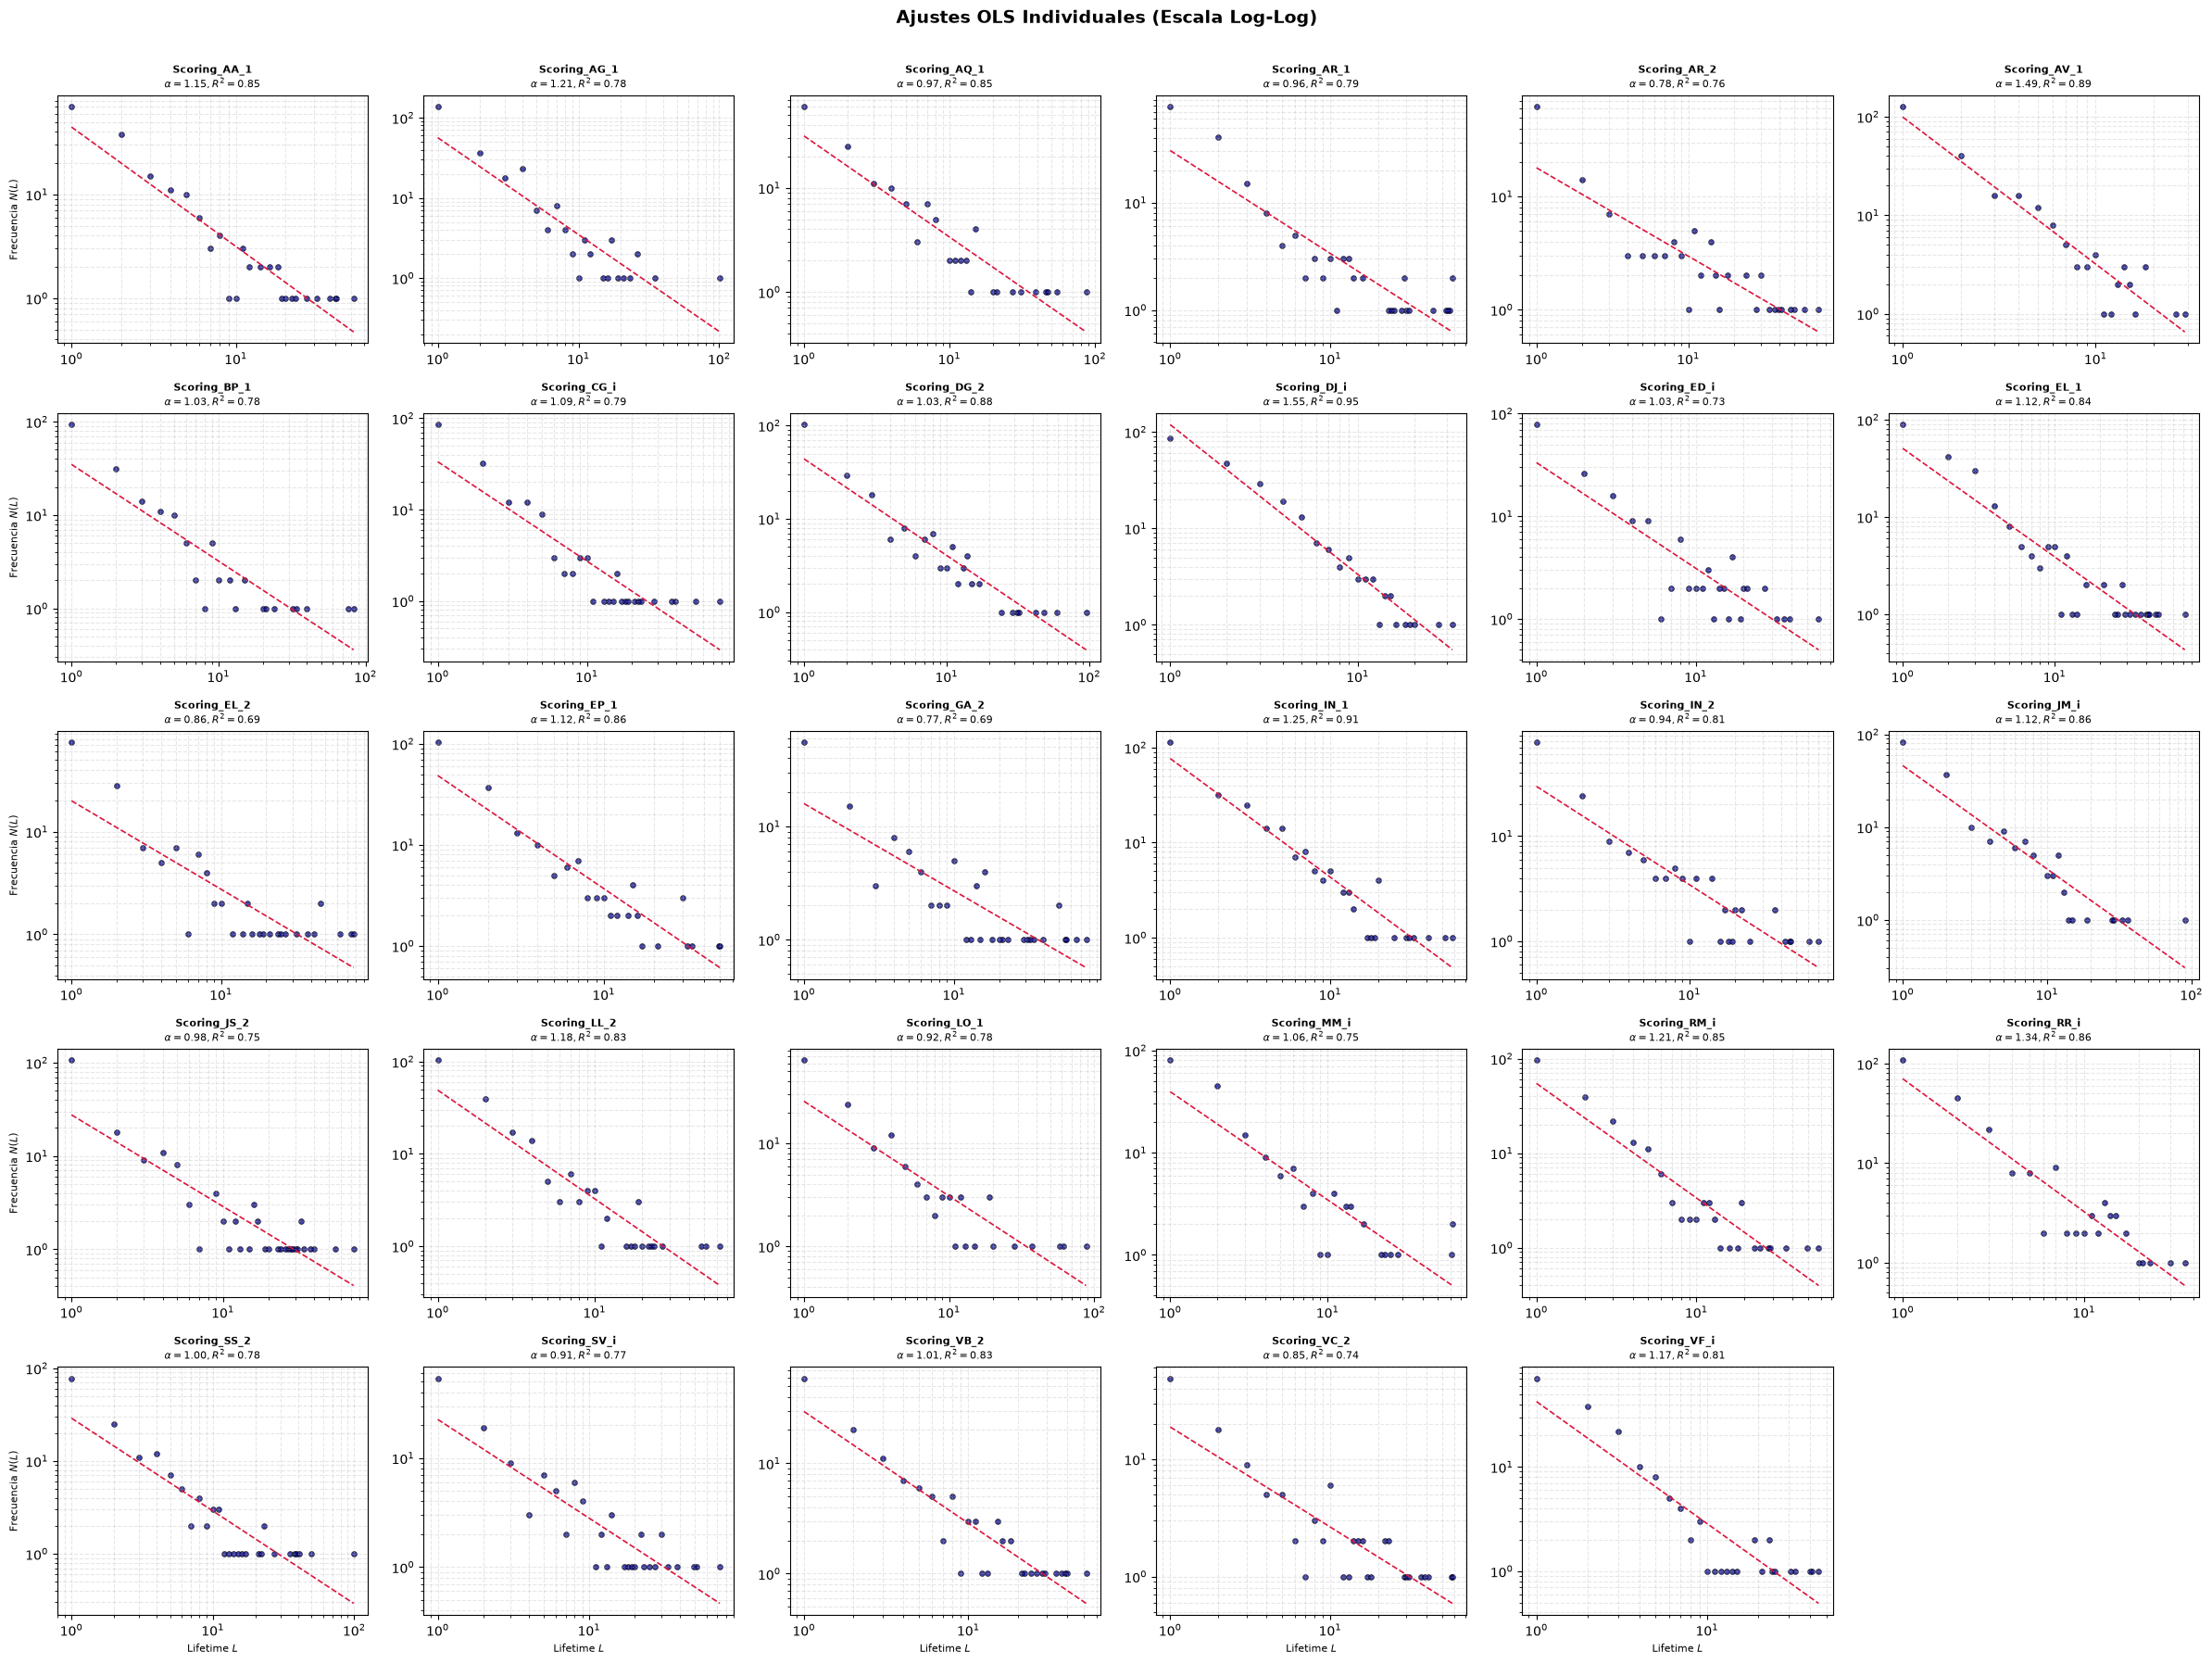

In [9]:
fig, axes = plt.subplots(5, 6, figsize=(24, 18), sharex=False, sharey=False)
axes = axes.flatten()

sujetos = list(hipnogramas.keys())

for i, sujeto in enumerate(sujetos):
    ax = axes[i]
    row = df_ols[df_ols['Sujeto'] == sujeto].iloc[0]

    lfts = calcular_lifetimes(hipnogramas[sujeto])
    valores, conteos = np.unique(lfts, return_counts=True)

    # Datos observados
    ax.scatter(valores, conteos, color='navy', alpha=0.75, edgecolors='black', linewidth=0.5, s=18, label='Datos')

    # Recta OLS: N(L) = 10^(intercepto) * L^(-alpha)
    l_fit = np.linspace(min(valores), max(valores), 100)
    n_fit = (10 ** row['intercept']) * (l_fit ** (-row['alpha_ols']))

    ax.plot(l_fit, n_fit, color='crimson', linestyle='--', linewidth=1.2, label='Ajuste OLS')

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f"{sujeto}\n$\\alpha={row['alpha_ols']:.2f}, R^2={row['r2']:.2f}$", fontsize=8, fontweight='bold')
    ax.grid(True, which="both", linestyle="--", alpha=0.3)

    if i % 6 == 0:
        ax.set_ylabel('Frecuencia $N(L)$', fontsize=8)
    if i >= 24:
        ax.set_xlabel('Lifetime $L$', fontsize=8)

# Eliminar el subgráfico 30 sobrante
if len(sujetos) < len(axes):
    for j in range(len(sujetos), len(axes)):
        fig.delaxes(axes[j])

plt.suptitle('Ajustes OLS Individuales (Escala Log-Log)', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.show()

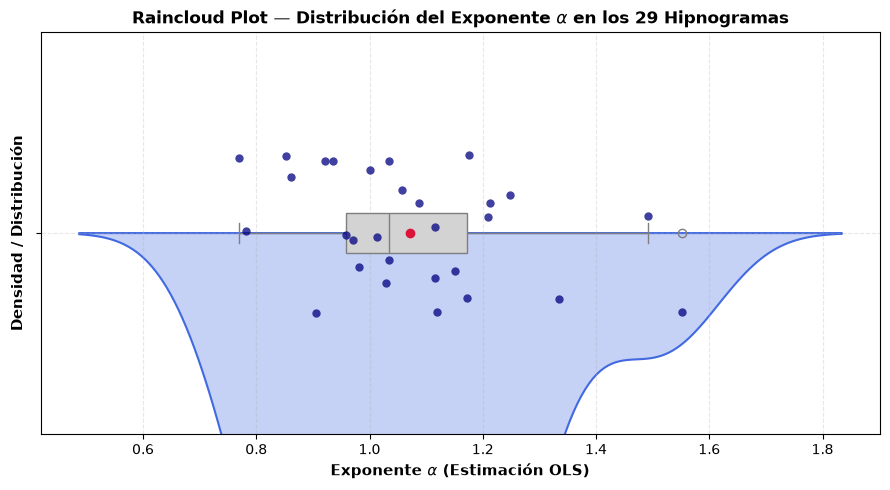

In [10]:
# Cargar los resultados previamente exportados
#df_ols = pd.read_csv('resultados_ols_29_hipnogramas.csv')

fig, ax = plt.subplots(figsize=(9, 5))

# 1. Diagrama de densidad (KDE)
sns.kdeplot(
    data=df_ols,
    x='alpha_ols',
    ax=ax,
    color='royalblue',
    fill=True,
    alpha=0.3,
    linewidth=1.5
)

# 2. Diagrama de caja (Boxplot alineado)
sns.boxplot(
    data=df_ols,
    x='alpha_ols',
    ax=ax,
    color='lightgray',
    width=0.1,
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "crimson", "markeredgecolor": "crimson", "markersize": 6}
)

# 3. Dispersión de puntos individuales con jitter (Strip plot)
sns.stripplot(
    data=df_ols,
    x='alpha_ols',
    ax=ax,
    color='navy',
    size=6,
    jitter=0.2,
    alpha=0.75
)

ax.set_xlabel(r'Exponente $\alpha$ (Estimación OLS)', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidad / Distribución', fontsize=11, fontweight='bold')
ax.set_title(r'Raincloud Plot — Distribución del Exponente $\alpha$ en los 29 Hipnogramas', fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

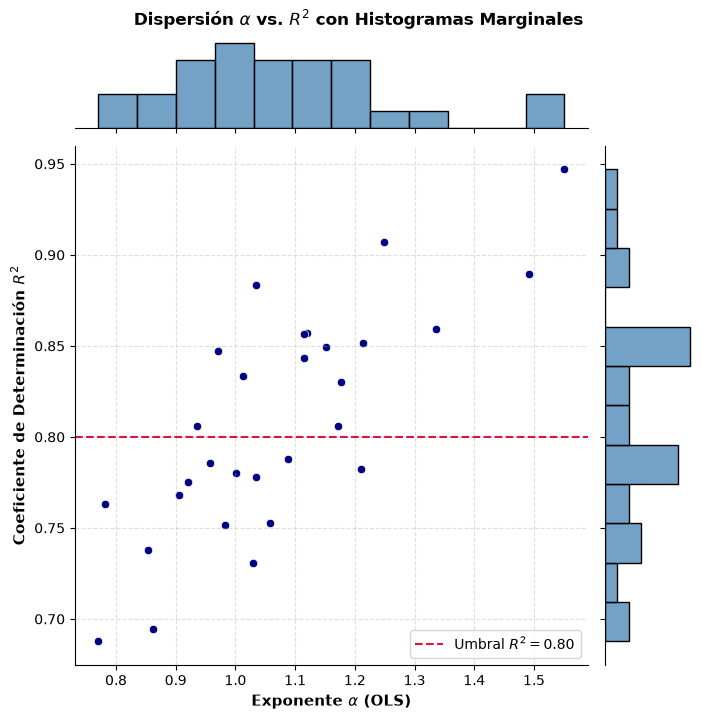

In [11]:
# Crear gráfico de dispersión con distribuciones marginales
g = sns.jointplot(
    data=df_ols,
    x='alpha_ols',
    y='r2',
    kind='scatter',
    color='navy',
    height=7,
    marginal_kws=dict(bins=12, fill=True, color='steelblue')
)

# Añadir línea punteada horizontal en el umbral crítico de R^2 = 0.80
g.ax_joint.axhline(0.80, color='crimson', linestyle='--', linewidth=1.5, label='Umbral $R^2 = 0.80$')

# Formato de ejes y leyenda
g.ax_joint.set_xlabel(r'Exponente $\alpha$ (OLS)', fontsize=11, fontweight='bold')
g.ax_joint.set_ylabel(r'Coeficiente de Determinación $R^2$', fontsize=11, fontweight='bold')
g.ax_joint.grid(True, linestyle='--', alpha=0.4)
g.ax_joint.legend(loc='lower right', fontsize=10)

g.fig.suptitle(r'Dispersión $\alpha$ vs. $R^2$ con Histogramas Marginales', y=1.02, fontsize=12, fontweight='bold')


plt.show()

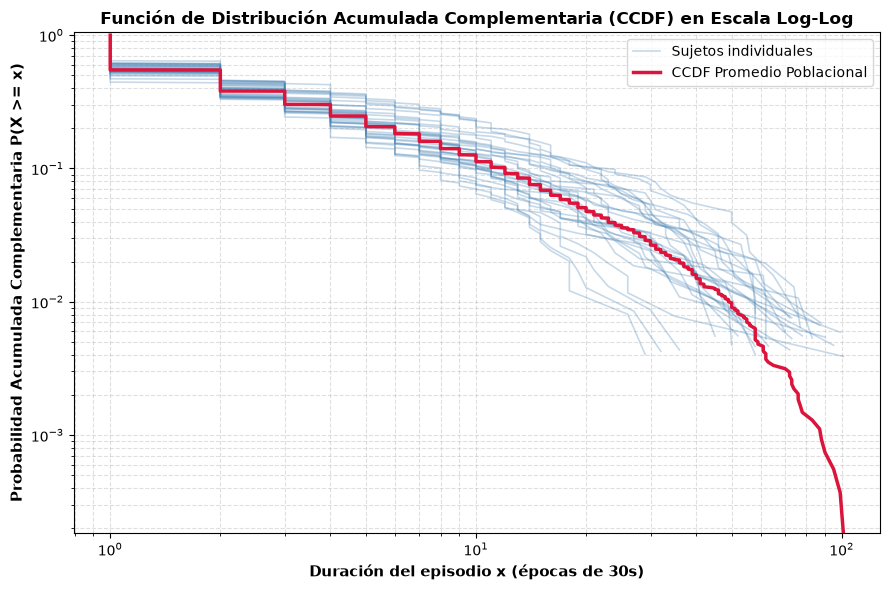

In [12]:
fig, ax = plt.subplots(figsize=(9, 6))

all_lifetimes = []

# Graficar las 29 CCDF empíricas individuales
for i, (sujeto, serie) in enumerate(hipnogramas.items()):
    lfts = np.array(calcular_lifetimes(serie))

    # 1. Eliminar valores <= 0 para no romper la escala logarítmica
    lfts = lfts[lfts > 0]
    if len(lfts) == 0:
        continue

    all_lifetimes.extend(lfts)

    # Cálculo de CCDF empírica: P(X >= x)
    sorted_l = np.sort(lfts)
    n = len(sorted_l)
    ccdf_y = 1.0 - (np.arange(n) / float(n))

    # Etiquetar solo el primer sujeto para no saturar la leyenda
    label_ind = 'Sujetos individuales' if i == 0 else None
    ax.plot(sorted_l, ccdf_y, color='steelblue', alpha=0.3, linewidth=1.2, label=label_ind)

# CCDF agregada (promedio poblacional)
sorted_all = np.sort(all_lifetimes)
n_all = len(sorted_all)

if n_all > 0:
    ccdf_all_y = 1.0 - (np.arange(n_all) / float(n_all))
    ax.plot(sorted_all, ccdf_all_y, color='crimson', linewidth=2.5, label='CCDF Promedio Poblacional')

# Escalas logarítmicas
ax.set_xscale('log')
ax.set_yscale('log')

# Fijar límite inferior visible para evitar error de y=0 en log
ax.set_ylim(bottom=1.0 / max(n_all, 1), top=1.05)

# Etiquetas usando '>=' directo (evita errores de LaTeX)
ax.set_xlabel('Duración del episodio x (épocas de 30s)', fontsize=11, fontweight='bold')
ax.set_ylabel('Probabilidad Acumulada Complementaria P(X >= x)', fontsize=11, fontweight='bold')
ax.set_title('Función de Distribución Acumulada Complementaria (CCDF) en Escala Log-Log', fontsize=12, fontweight='bold')

ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

### Método Clauset

### Interpretación de P-Value



## Comparación de los métodos


## Análisis con N-Gramas


### qué $n$-grama se parece más a una ley de potencia

## 6. Teoría de la información
Se analizaran los siguientes grupos:
- **Grupo A**: Datos de los hipnogramas terminacion '2'
- **Grupo B**: Datos de los hipnogramas terminacion 'i'
- **Grupo C**: Datos de A + B

In [22]:
grupo_A = {k: v for k, v in hipnogramas_np.items() if k.endswith('_2')}
grupo_B = {k: v for k, v in hipnogramas_np.items() if k.endswith('_i')}
grupo_C = {**grupo_A, **grupo_B}

K = 8  # simbolos 0..7 (incluye 6=Movimiento, 7=Sin clasificar; se mantienen)

print(f"Grupo A (..._2): Individuos:{len(grupo_A)} -> {sorted(grupo_A.keys())}")
print(f"Grupo B (..._i): Individuos:{len(grupo_B)} -> {sorted(grupo_B.keys())}")
print(f"Grupo C (A+B): {len(grupo_C)}")
print(f"K = {K} simbolos; longitudes medias: A={np.mean([len(v) for v in grupo_A.values()]):.1f}, B={np.mean([len(v) for v in grupo_B.values()]):.1f}")

Grupo A (..._2): Individuos:10 -> ['Scoring_AR_2', 'Scoring_DG_2', 'Scoring_EL_2', 'Scoring_GA_2', 'Scoring_IN_2', 'Scoring_JS_2', 'Scoring_LL_2', 'Scoring_SS_2', 'Scoring_VB_2', 'Scoring_VC_2']
Grupo B (..._i): Individuos:9 -> ['Scoring_CG_i', 'Scoring_DJ_i', 'Scoring_ED_i', 'Scoring_JM_i', 'Scoring_MM_i', 'Scoring_RM_i', 'Scoring_RR_i', 'Scoring_SV_i', 'Scoring_VF_i']
Grupo C (A+B): 19
K = 8 simbolos; longitudes medias: A=950.1, B=850.2


In [ ]:
def entropia(conteos: np.ndarray) -> float:
    """Entropía de Shannon (bits) a partir de un vector de conteos."""
    p = conteos[conteos > 0] / conteos.sum()
    return -np.sum(p * np.log2(p))

def medidas_info(x: np.ndarray, y: np.ndarray, K: int):
    """Devuelve H(X), H(Y), H(X,Y), H(Y|X) e I(X;Y) para pares alineados."""
    h_x = entropia(np.bincount(x, minlength=K))
    h_y = entropia(np.bincount(y, minlength=K))
    h_xy = entropia(np.bincount(x * K + y, minlength=K * K))
    # Return H(X), H(Y), H(X,Y), H(X|Y), I(X,Y)
    return h_x, h_y, h_xy, h_xy - h_x, h_x + h_y - h_xy

In [25]:
# Se calculan todas las metricas y se grafican los resultados (solo promedio grupal):
# Barrido tau=1..360 (180 ~= ciclo ultradiano 90 min; 360 ~= 3 h). Nota: con tau=1 unico
# no se puede detectar periodicidad (objetivos 6-7 exigen curva vs tau).
taus = np.arange(1, 361)
grupos = {
    'A (_2)': grupo_A,
    'B (_i)': grupo_B,
    'C (A+B)': grupo_C
    }
# curvas[grupo][medida] -> array (len(taus),)
medidas = ['H_marg', 'H_conj', 'H_cond', 'I_mutua']
curvas_mean = {g: {m: np.zeros(len(taus)) for m in medidas} for g in grupos}
curvas_std = {g: {m: np.zeros(len(taus)) for m in medidas} for g in grupos}

for gi, (gname, gdict) in enumerate(grupos.items()):
    sujetos_g = list(gdict.keys())
    # matriz temporal: (n_sujetos, n_taus) por medida
    tmp = {m: np.zeros((len(sujetos_g), len(taus))) for m in medidas}
    for si, s in enumerate(sujetos_g):
        s_serie = np.asarray(gdict[s], dtype=int)
        for ti, tau in enumerate(taus):
            if tau >= len(s_serie):
                tmp['H_marg'][si, ti] = np.nan
                tmp['H_conj'][si, ti] = np.nan
                tmp['H_cond'][si, ti] = np.nan
                tmp['I_mutua'][si, ti] = np.nan
                continue
            x = s_serie[:-tau]
            y = s_serie[tau:]
            h_x, h_y, h_xy, h_cond, mi = medidas_info(x, y, K)
            tmp['H_marg'][si, ti] = (h_x + h_y) / 2  # promedio H(X),H(Y) para curva estable
            tmp['H_conj'][si, ti] = h_xy
            tmp['H_cond'][si, ti] = h_cond
            tmp['I_mutua'][si, ti] = mi
    for m in medidas:
        curvas_mean[gname][m] = np.nanmean(tmp[m], axis=0)
        curvas_std[gname][m] = np.nanstd(tmp[m], axis=0)
    print(f"{gname}: n={len(sujetos_g)} | I(tau=1)={curvas_mean[gname]['I_mutua'][0]:.3f} bits | "
          f"H_cond(1)={curvas_mean[gname]['H_cond'][0]:.3f} | H_marg(1)={curvas_mean[gname]['H_marg'][0]:.3f}")

A (_2): n=10 | I(tau=1)=1.401 bits | H_cond(1)=0.767 | H_marg(1)=2.168
B (_i): n=9 | I(tau=1)=1.456 bits | H_cond(1)=0.987 | H_marg(1)=2.442
C (A+B): n=19 | I(tau=1)=1.427 bits | H_cond(1)=0.871 | H_marg(1)=2.298


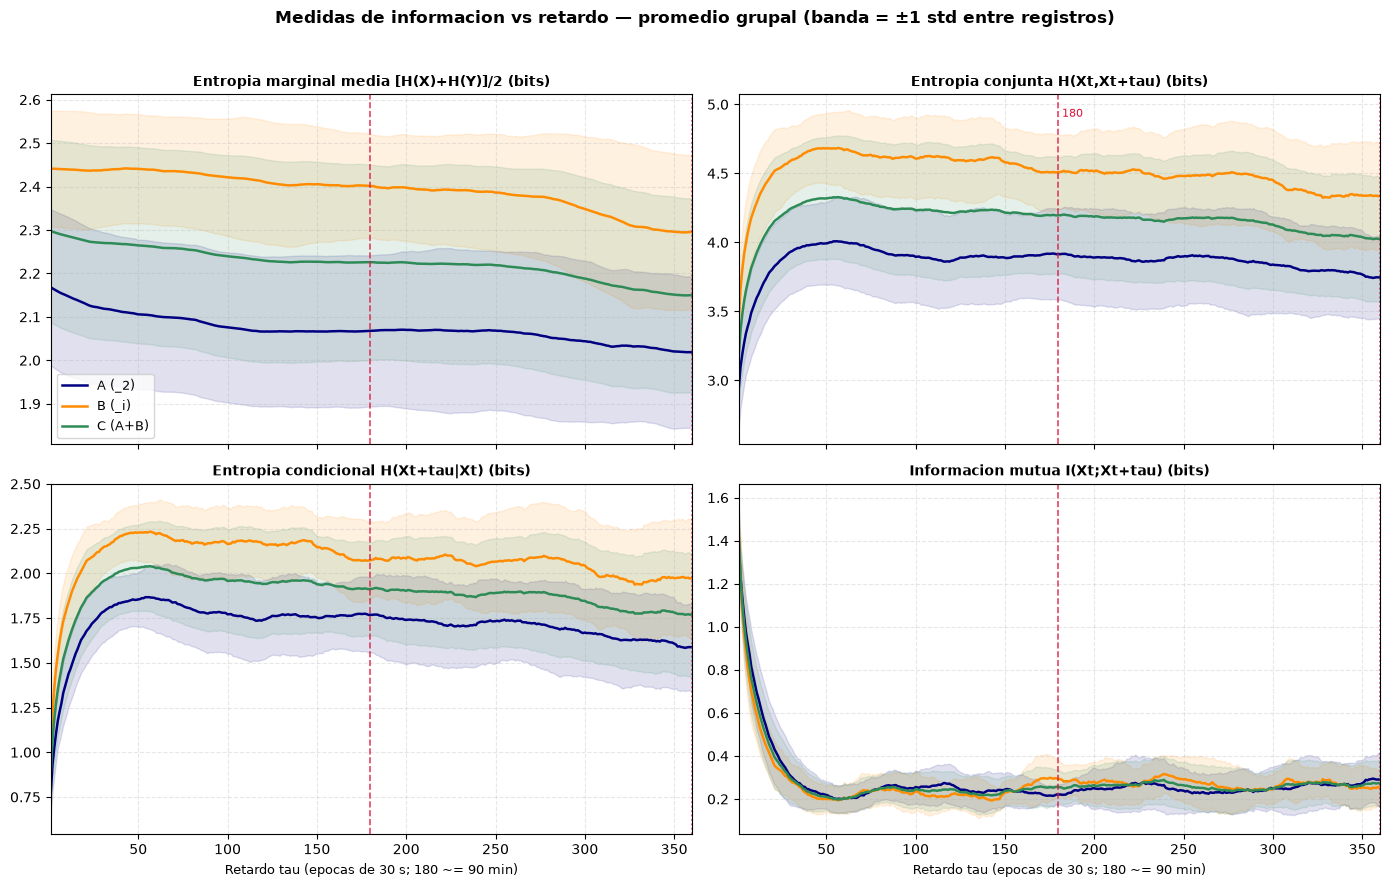

  Grupo  tau   H_marg   H_conj   H_cond  I_mutua
 A (_2)    1 2.168013 2.934841 0.767126 1.401185
 A (_2)   90 2.083291 3.907654 1.779754 0.258928
 A (_2)  180 2.067668 3.915395 1.768753 0.219942
 A (_2)  360 2.017977 3.746404 1.587857 0.289550
 B (_i)    1 2.442044 3.427760 0.986564 1.456327
 B (_i)   90 2.425850 4.612190 2.168050 0.239510
 B (_i)  180 2.401278 4.507951 2.072980 0.294604
 B (_i)  360 2.295647 4.338785 1.973659 0.252509
C (A+B)    1 2.297817 3.168329 0.871070 1.427305
C (A+B)   90 2.245556 4.241381 1.963684 0.249730
C (A+B)  180 2.225694 4.196079 1.912860 0.255308
C (A+B)  360 2.149505 4.027005 1.770605 0.272004


In [ ]:
## Plot Entropy
plot_h = True
if plot_h :
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    panel = {'H_marg': (0, 0, 'Entropia marginal media [H(X)+H(Y)]/2 (bits)'),
            'H_conj': (0, 1, 'Entropia conjunta H(Xt,Xt+tau) (bits)'),
            'H_cond': (1, 0, 'Entropia condicional H(Xt+tau|Xt) (bits)'),
            'I_mutua': (1, 1, 'Informacion mutua I(Xt;Xt+tau) (bits)')}
    colores = {'A (_2)': 'navy', 'B (_i)': 'darkorange', 'C (A+B)': 'seagreen'}
    for m, (r, c, titulo) in panel.items():
        ax = axes[r, c]
        for gname in grupos:
            ax.plot(taus, curvas_mean[gname][m], color=colores[gname], lw=1.8, label=gname)
            ax.fill_between(taus, curvas_mean[gname][m] - curvas_std[gname][m],
                            curvas_mean[gname][m] + curvas_std[gname][m],
                            color=colores[gname], alpha=0.12)
        ax.axvline(180, color='crimson', ls='--', lw=1.2, alpha=0.8)
        ax.axvline(360, color='crimson', ls=':', lw=1.2, alpha=0.8)
        ax.set_title(titulo, fontsize=10, fontweight='bold')
        ax.grid(True, ls='--', alpha=0.3)
        ax.set_xlim(1, 360)
        if r == 1:
            ax.set_xlabel('Retardo tau (epocas de 30 s; 180 ~= 90 min)', fontsize=9)
    axes[0, 0].legend(fontsize=9, loc='best')
    axes[0, 1].text(182, axes[0, 1].get_ylim()[1]*0.98, '180', color='crimson', fontsize=8, va='top')
    fig.suptitle('Medidas de informacion vs retardo — promedio grupal (banda = ±1 std entre registros)', fontsize=12, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig('info_medidas_vs_tau_grupos.png', dpi=200)
    plt.show()

    # Tabla comparativa en retardos clave para justificar eleccion (tau=1, 90, 180, 360)
    import pandas as pd
    filas = []
    for gname in grupos:
        for tau_sel in [1, 90, 180, 360]:
            idx = tau_sel - 1
            filas.append({'Grupo': gname, 'tau': tau_sel,
                        'H_marg': curvas_mean[gname]['H_marg'][idx],
                        'H_conj': curvas_mean[gname]['H_conj'][idx],
                        'H_cond': curvas_mean[gname]['H_cond'][idx],
                        'I_mutua': curvas_mean[gname]['I_mutua'][idx]})
    df_info_taus = pd.DataFrame(filas)
    print(df_info_taus.to_string(index=False))

In [ ]:
display(df_info_taus.head())

,Grupo,tau,H_marg,H_conj,H_cond,I_mutua
0,A (_2),1,2.168013,2.934841,0.767126,1.401185
1,A (_2),90,2.083291,3.907654,1.779754,0.258928
2,A (_2),180,2.067668,3.915395,1.768753,0.219942
3,A (_2),360,2.017977,3.746404,1.587857,0.289550
4,B (_i),1,2.442044,3.427760,0.986564,1.456327


## 6.1 Teoría de la información con 6 símbolos

Reducción de las etapas de 8 a 6 símbolos:

| Original | Etapa | Nuevo símbolo |
| --- | --- | --- |
| 0 | W (vigilia) | 0 (W) |
| 1 | Etapa 1 | 1 (E1) |
| 2 | Etapa 2 | 2 (E2) |
| 5 | REM | 3 (REM) |
| 3, 4 | Etapas 3 y 4 | 4 (Deep Sleep) |
| 6, 7 | Movimiento / Sin clasificar | 5 (Artefacto) |


In [18]:
# Mapeo 8 -> 6 simbolos: 0=W, 1=E1, 2=E2, 3=REM, 4=Deep (3+4), 5=Artefacto (6+7)
MAPA_6 = np.array([0, 1, 2, 4, 4, 3, 5, 5])
K6 = 6

def reducir_etapas(serie: np.ndarray) -> np.ndarray:
    """Reduce una serie de simbolos 0..7 a 0..5 segun MAPA_6."""
    return MAPA_6[np.asarray(serie, dtype=int)]

grupo_A_6 = {k: reducir_etapas(v) for k, v in grupo_A.items()}
grupo_B_6 = {k: reducir_etapas(v) for k, v in grupo_B.items()}
grupo_C_6 = {**grupo_A_6, **grupo_B_6}

# Validaciones: rango de simbolos y conservacion del numero de epocas
for g_orig, g_red in [(grupo_A, grupo_A_6), (grupo_B, grupo_B_6)]:
    for k in g_orig:
        assert len(g_orig[k]) == len(g_red[k]), f"Longitud distinta en {k}"
        assert g_red[k].max() <= 5 and g_red[k].min() >= 0, f"Valor fuera de rango en {k}"

conteo_orig = np.bincount(np.concatenate(list(grupo_C.values())).astype(int), minlength=8)
conteo_red = np.bincount(np.concatenate(list(grupo_C_6.values())), minlength=6)
print("Conteos originales (0..7):", conteo_orig)
print("Conteos reducidos  (0..5):", conteo_red)
print("Proporciones reducidas:", np.round(conteo_red / conteo_red.sum(), 3))


Conteos originales (0..7): [1293 1027 7400  909 2500 2994  790  240]
Conteos reducidos  (0..5): [1293 1027 7400 2994 3409 1030]
Proporciones reducidas: [0.075 0.06  0.431 0.175 0.199 0.06 ]


A (_2) (K=6): n=10 | I(tau=1)=1.248 bits
B (_i) (K=6): n=9 | I(tau=1)=1.351 bits
C (A+B) (K=6): n=19 | I(tau=1)=1.297 bits
Validacion K=6 tau=1 OK.


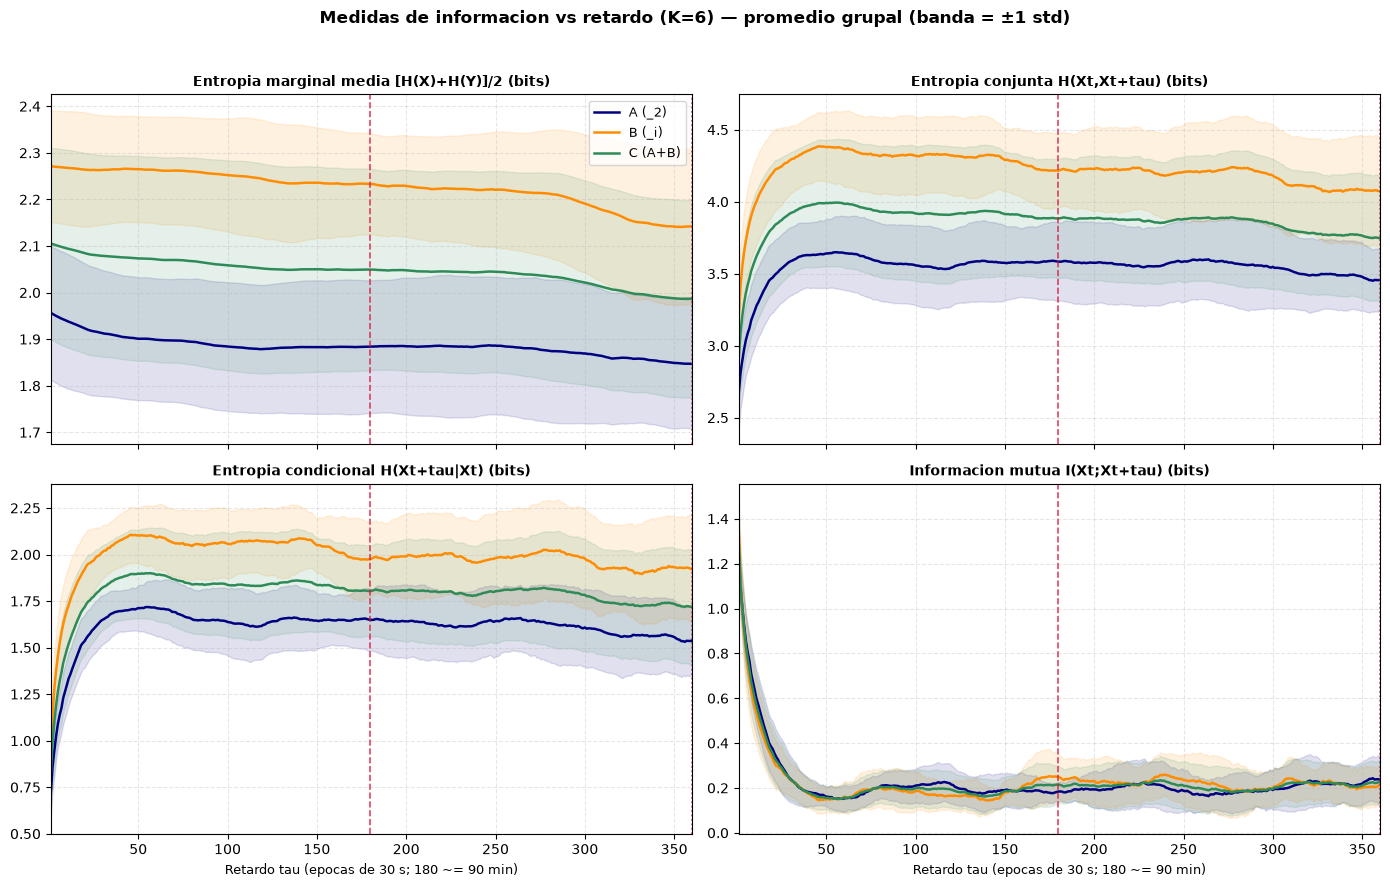

  Grupo  tau  H_marg_K8  H_marg_K6  H_conj_K8  H_conj_K6  H_cond_K8  H_cond_K6  I_mutua_K8  I_mutua_K6
 A (_2)    1      2.168      1.956      2.935      2.665      0.767      0.709       1.401       1.248
 A (_2)   90      2.083      1.888      3.908      3.567      1.780      1.646       0.259       0.209
 A (_2)  180      2.068      1.884      3.915      3.584      1.769      1.649       0.220       0.184
 A (_2)  360      2.018      1.847      3.746      3.456      1.588      1.537       0.290       0.237
 B (_i)    1      2.442      2.272      3.428      3.192      0.987      0.920       1.456       1.351
 B (_i)   90      2.426      2.256      4.612      4.321      2.168      2.057       0.240       0.191
 B (_i)  180      2.401      2.233      4.508      4.216      2.073      1.975       0.295       0.250
 B (_i)  360      2.296      2.142      4.339      4.072      1.974      1.921       0.253       0.213
C (A+B)    1      2.298      2.106      3.168      2.915      0.871      

In [19]:

# Recalculo de metricas con K=6 (mismo barrido tau=1..360 y misma logica que la seccion 6)
grupos_6 = {'A (_2)': grupo_A_6, 'B (_i)': grupo_B_6, 'C (A+B)': grupo_C_6}
curvas_mean_6 = {g: {m: np.zeros(len(taus)) for m in medidas} for g in grupos_6}
curvas_std_6 = {g: {m: np.zeros(len(taus)) for m in medidas} for g in grupos_6}

for gname, gdict in grupos_6.items():
    sujetos_g = list(gdict.keys())
    tmp = {m: np.full((len(sujetos_g), len(taus)), np.nan) for m in medidas}
    for si, s in enumerate(sujetos_g):
        s_serie = np.asarray(gdict[s], dtype=int)
        for ti, tau in enumerate(taus):
            if tau >= len(s_serie):
                continue
            x = s_serie[:-tau]
            y = s_serie[tau:]
            h_x, h_y, h_xy, h_cond, mi = medidas_info(x, y, K6)
            tmp['H_marg'][si, ti] = (h_x + h_y) / 2
            tmp['H_conj'][si, ti] = h_xy
            tmp['H_cond'][si, ti] = h_cond
            tmp['I_mutua'][si, ti] = mi
    for m in medidas:
        curvas_mean_6[gname][m] = np.nanmean(tmp[m], axis=0)
        curvas_std_6[gname][m] = np.nanstd(tmp[m], axis=0)
    print(f"{gname} (K=6): n={len(sujetos_g)} | I(tau=1)={curvas_mean_6[gname]['I_mutua'][0]:.3f} bits")

for gname in grupos_6:
    assert curvas_mean_6[gname]['I_mutua'][0] > 0, f"I(tau=1)<=0 en {gname}"
    assert curvas_mean_6[gname]['H_cond'][0] < curvas_mean_6[gname]['H_marg'][0], f"H_cond>=H_marg en {gname}"
print("Validacion K=6 tau=1 OK.")

# Figura 2x2 con K=6 (mismos paneles y colores que la seccion 6)
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for m, (r, c, titulo) in panel.items():
    ax = axes[r, c]
    for gname in grupos_6:
        ax.plot(taus, curvas_mean_6[gname][m], color=colores[gname], lw=1.8, label=gname)
        ax.fill_between(taus, curvas_mean_6[gname][m] - curvas_std_6[gname][m],
                        curvas_mean_6[gname][m] + curvas_std_6[gname][m],
                        color=colores[gname], alpha=0.12)
    ax.axvline(180, color='crimson', ls='--', lw=1.2, alpha=0.8)
    ax.axvline(360, color='crimson', ls=':', lw=1.2, alpha=0.8)
    ax.set_title(titulo, fontsize=10, fontweight='bold')
    ax.grid(True, ls='--', alpha=0.3)
    ax.set_xlim(1, 360)
    if r == 1:
        ax.set_xlabel('Retardo tau (epocas de 30 s; 180 ~= 90 min)', fontsize=9)
axes[0, 0].legend(fontsize=9, loc='best')
fig.suptitle('Medidas de informacion vs retardo (K=6) — promedio grupal (banda = ±1 std)', fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('info_medidas_vs_tau_grupos_K6.png', dpi=200)
plt.show()

# Tabla comparativa K=8 vs K=6 en taus clave
filas_cmp = []
for gname in grupos_6:
    for tau_sel in [1, 90, 180, 360]:
        idx = tau_sel - 1
        fila = {'Grupo': gname, 'tau': tau_sel}
        for m in medidas:
            v8 = curvas_mean[gname][m][idx]
            v6 = curvas_mean_6[gname][m][idx]
            fila[f'{m}_K8'] = v8
            fila[f'{m}_K6'] = v6
        filas_cmp.append(fila)
df_info_taus_6 = pd.DataFrame(filas_cmp)
print(df_info_taus_6.round(3).to_string(index=False))


## Interpretación de los resultados


Esta celda es unicamente para verificar que las ramas y los push y pull esten bien